In [ ]:
import pandas as pd
import numpy as np

df_main = pd.read_csv('final_sales_dataset.csv')

# Descriptors:city, family, promo_mean (avg promotion intensity of series, low medium high), promo_slope (trend in promotion intensity, low medium high)
# Target: sales (one trajectory per series)

In [ ]:
df_main.head(5)

,id,date,store_nbr,family,sales,onpromotion,city,oil_price,holiday
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,NaN,True
1,2,2013-01-01,1,BEAUTY,0.0,0,Quito,NaN,True
2,3,2013-01-01,1,BEVERAGES,0.0,0,Quito,NaN,True
3,4,2013-01-01,1,BOOKS,0.0,0,Quito,NaN,True
4,5,2013-01-01,1,BREAD/BAKERY,0.0,0,Quito,NaN,True


# Task:
Apply beam search to Store sales dataset. Use RCS and Rank-biserial correlation.

In [ ]:
import time, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

N, T, LITS, OUT, SIG2, DMU = 500, 24, 3, 0.2, 5, 1
D_MAX, Q, W, W_WIDE, U, MIN_COV = 3, 5, 20, 200, 150, 0.01
K_VALUES = [8, 16, 24, 32]
REPS = 10


class Quality:
    def __init__(self, Y):
        self.D = cdist(Y, Y)
        self.rowsum = self.D.sum(1)
        self.cache = {}

    def __call__(self, m):
        key = m.tobytes()
        if key not in self.cache:
            n = m.sum()
            if n < max(2, MIN_COV * len(m)) or n == len(m):
                self.cache[key] = None
            else:
                s = self.D @ m
                within = s[m].sum()
                beta = within / (n * (n - 1))
                alpha = (self.rowsum[m].sum() - within) / (n * (len(m) - n))
                self.cache[key] = alpha / (beta + 1)
        return self.cache[key]

def mask_of(A, desc):
    m = np.ones(len(A), bool)
    for j, v in desc:
        m &= A[:, j] == v
    return m


def beam_search(A, qual, w=W):
    k = A.shape[1]
    conds = [(j, v) for j in range(k) for v in (0, 1)]
    results, seeds, seen = {}, [()], set()
    for _ in range(D_MAX):
        beam = []
        for seed in seeds:
            used = {j for j, _ in seed}
            for c in conds:
                if c[0] in used:
                    continue
                desc = tuple(sorted(seed + (c,)))
                if desc in seen:
                    continue
                seen.add(desc)
                m = mask_of(A, desc)
                phi = qual(m)
                if phi is not None:
                    results[desc] = (phi, m)
                    beam.append((phi, desc))
        beam.sort(reverse=True)
        seeds = [d for _, d in beam[:w]]
    top = sorted(results.values(), key=lambda x: -x[0])[:Q]
    return top, len(seen)

## Check for skewness

Right-skewness of sales attributes, indicating use of rank-biserial correlation rather than RCS.

In [ ]:
import time
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist

D_MAX, K, W, MIN_COV = 3, 5, 20, 0.01

def tertiles(x):
    return pd.qcut(x.rank(method='first'), 3, labels=['low', 'medium', 'high'])
 
 
def build_data(path='final_sales_dataset.csv', lead_zero_frac=0.1):
    """
    - Y:     target, one row per store x family series = weekly sales, z-scored within the series
    - A:     binary descriptor matrix (rows = series, cols = "attribute == value")
    - names: labels of A's columns, same order
    - meta:  readable table per series: store_nbr (identifier only) + descriptor values
    """
    df = pd.read_csv(path, parse_dates=['date'])
    g = df.set_index('date').groupby(['store_nbr', 'family'])
 
    weekly = g['sales'].resample('W').sum().unstack('date').fillna(0)
    mu, sd = weekly.mean(1), weekly.std(1)
 
    first_sale = (weekly > 0).to_numpy().argmax(1)
    keep = ((sd > 0).to_numpy()
            & (first_sale < lead_zero_frac * weekly.shape[1]))
    Y = weekly[keep].sub(mu[keep], axis=0).div(sd[keep], axis=0)

    promo = (g['onpromotion'].resample('W').mean().unstack('date')
               .reindex(index=Y.index, columns=weekly.columns).fillna(0))
    t = np.arange(promo.shape[1], dtype=float)
    t -= t.mean()
    promo_mean = promo.mean(1)
    promo_slope = promo.sub(promo_mean, axis=0).mul(t, axis=1).sum(1) / (t ** 2).sum()
 
    # descriptor table 
    meta = (df.groupby(['store_nbr', 'family']).agg(city=('city', 'first')).loc[Y.index].reset_index())
    meta['promo_mean'] = tertiles(promo_mean.reset_index(drop=True))
    meta['promo_slope'] = tertiles(promo_slope.reset_index(drop=True))

    descriptors = ['city', 'family', 'promo_mean', 'promo_slope']
    onehot = pd.get_dummies(meta[descriptors].astype(str), prefix_sep='=')
    A = onehot.to_numpy(dtype=np.int8)

    Y = pd.DataFrame(
        Y,
        index=pd.MultiIndex.from_frame(meta[['store_nbr', 'family']]),
    )
 
    return Y, A, list(onehot.columns), meta


# 2. Quality measure: rank-biserial correlation of between vs within distances
#    r = P(between > within) - P(between < within), in [-1, 1]
# 
class RankBiserial:
    """
    Compares between-distance and within-distance with within meaning both series are in subgroup s,
    and between meaning one series is in s and the other is not. The rank-biserial correlation
    is the difference between the probability that a between-distance is greater than a within-distance
    r = P(between > within) - P(between < within), which is equivalent to r = 2 * U / (nm) - 1, where
    U is the number of combinations where between distance > within distance.
    """

    def __init__(self, Y):
        i, j = np.triu_indices(len(Y), k=1)
        d = cdist(Y, Y)[i, j]
        order = np.argsort(d, kind='stable')
        self.i, self.j = i[order], j[order]
        self.cache = {}

    def __call__(self, m):
        key = m.tobytes()
        if key not in self.cache:
            n, N = m.sum(), len(m)
            if n < max(2, MIN_COV * N) or n == N:
                self.cache[key] = None
            else:
                a, b = m[self.i], m[self.j]
                within = a & b
                between = a ^ b
                # U: no. of combinations where between distance > within distance
                U = np.cumsum(within, dtype=np.int64)[between].sum()

                nw = n * (n - 1) // 2  # m in (C.5): number of within pairs
                nb = n * (N - n) # n in (C.5): number of between pairs

                self.cache[key] = 2 * U / (nb * nw) - 1 # r = 2U / (nm) - 1, with r in [-1, 1]

        return self.cache[key]

def mask_of(A, desc):
    m = np.ones(len(A), bool)
    for j, v in desc:
        m &= A[:, j] == v
    return m


def beam_search(A, qual, K=K, w=W, D=D_MAX, positive_only=True):
    # D = max depth of beam search
    # w = beam width
    # A = binary matrix of descriptors (rows = series, cols = attribute==value)
    # qual = quality measure (callable)
    # K = best K descriptors to return
    
    k = A.shape[1]
    values = (1,) if positive_only else (0, 1)

    # 'conds' has that (j, v) is a condition with column j of A and value v
    conds = [(j, v) for j in range(k) for v in values]
    
    # 'seeds' starts from empty descriptor, then grows by adding one condition at a time
    results, seeds, seen = {}, [()], set()
    for _ in range(D):
        beam = []
        for seed in seeds:
            used = {j for j, _ in seed}
            for c in conds:
                if c[0] in used:
                    continue
                # add condition c to the current seed descriptor, sort to canonical order
                desc = tuple(sorted(seed + (c,)))
                if desc in seen:
                    continue
                seen.add(desc)
                m = mask_of(A, desc)
                phi = qual(m)
                if phi is not None:
                    results[desc] = (phi, m)
                    beam.append((phi, desc))
        # keep top w descriptors w/ highest quality
        beam.sort(reverse=True)
        seeds = [d for _, d in beam[:w]]

    best = {}
    for desc, (phi, m) in results.items():
        key = m.tobytes()
        if key not in best or len(desc) < len(best[key][0]):
            best[key] = (desc, phi, m)
    # return top K descriptors w/ highest quality across all levels
    top = sorted(best.values(), key=lambda x: -x[1])[:K]
    return top, len(seen)

def describe(desc, names):
    return ' AND '.join(names[j] if v == 1 else f'NOT {names[j]}' for j, v in desc)

Y, A, names, meta = build_data()


In [ ]:
# what the first series represents
print(meta.iloc[0])

# show Y as pandas Dataframe
df = pd.DataFrame(Y)
df.columns = [f'week_{i}' for i in df.columns]
df.index = [f'series_{i}' for i in df.index]
df

store_nbr               1
family         AUTOMOTIVE
city                Quito
promo_mean            low
promo_slope           low
Name: 0, dtype: object


,week_2013-01-06 00:00:00,week_2013-01-13 00:00:00,week_2013-01-20 00:00:00,week_2013-01-27 00:00:00,week_2013-02-03 00:00:00,week_2013-02-10 00:00:00,week_2013-02-17 00:00:00,week_2013-02-24 00:00:00,week_2013-03-03 00:00:00,week_2013-03-10 00:00:00,...,week_2017-06-18 00:00:00,week_2017-06-25 00:00:00,week_2017-07-02 00:00:00,week_2017-07-09 00:00:00,week_2017-07-16 00:00:00,week_2017-07-23 00:00:00,week_2017-07-30 00:00:00,week_2017-08-06 00:00:00,week_2017-08-13 00:00:00,week_2017-08-20 00:00:00
"series_(1, 'AUTOMOTIVE')",-0.871707,-1.100382,-1.100382,-0.757369,-0.986045,-0.986045,-2.358097,-0.871707,-1.557733,-1.786409,...,0.386008,1.300710,1.072034,0.042995,1.758061,1.300710,1.186372,1.872398,1.415047,-2.015084
"series_(1, 'BEAUTY')",-1.303685,-1.006051,-0.261967,-1.898953,-0.261967,-0.559601,-1.452502,-0.708418,-1.006051,-0.708418,...,1.077385,2.565554,1.672652,1.077385,1.672652,0.482117,0.333301,1.375019,1.375019,-1.006051
"series_(1, 'BEVERAGES')",-1.611233,-1.008624,-0.968335,-1.118369,-1.244922,-1.444885,-1.693789,-1.254067,-1.232069,-1.049408,...,1.232004,1.227555,0.952203,1.196905,0.995459,1.096800,0.870636,1.041680,0.398287,-1.706889
"series_(1, 'BREAD/BAKERY')",-2.283106,-0.867480,-1.028703,-0.732977,-1.172207,-1.622830,-1.951997,-0.596817,-1.069514,-0.966561,...,0.307374,0.660346,0.232965,0.412178,-0.253743,0.208598,-0.129013,-0.243699,-0.796310,-4.135171
"series_(1, 'CLEANING')",-1.244225,0.641602,0.383679,-0.352709,0.170612,-0.384482,-2.260964,-0.025633,-0.259259,0.344430,...,-0.094786,0.834110,0.615436,0.707017,0.239766,0.772432,-0.300377,0.105197,-1.384401,-5.948513
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"series_(54, 'MEATS')",-1.560854,-0.790663,0.121677,-0.879560,-1.411811,-1.542239,-0.940922,0.151186,-0.603087,-1.077361,...,1.676442,0.161938,0.726678,-0.004361,0.388895,1.004508,0.427359,0.385722,0.208070,-4.237412
"series_(54, 'PERSONAL CARE')",-0.884345,-0.484231,-0.781459,-1.231111,-0.434693,-1.333997,-1.833187,-1.166330,-0.556633,-1.090118,...,0.205490,-0.015526,0.487475,0.354103,-0.084117,0.026391,0.167383,0.594172,-0.167950,-3.422212
"series_(54, 'POULTRY')",-2.479474,-2.116440,-1.912391,-1.710062,-1.590710,-1.359236,-1.700337,-1.887008,-0.905200,-1.571863,...,1.562224,0.134032,0.975369,1.058447,1.567292,1.800143,0.235041,1.195147,1.203604,-2.529636
"series_(54, 'PREPARED FOODS')",-1.818363,-0.916855,-1.109485,-1.309820,-1.309820,-0.308144,-2.003288,-1.494745,-1.386872,-1.201948,...,2.188340,1.749144,1.017150,1.394705,0.524017,1.826196,1.371589,1.772260,0.901572,-1.425398


In [ ]:

Y, A, names, meta = build_data()

print(f'{Y.shape[0]} series x {Y.shape[1]} weeks, {A.shape[1]} binary descriptors')

t0 = time.time()
top, n_eval = beam_search(A, RankBiserial(Y))
print(f'{n_eval} candidates evaluated in {time.time() - t0:.0f}s\n')

for desc, phi, m in top:
    print(f'r = {phi:.3f}  n = {m.sum():4d}  {describe(desc, names)}')

993 series x 242 weeks, 48 binary descriptors
1667 candidates evaluated in 1s

r = 0.995  n =   13  city=Quito AND family=PRODUCE
r = 0.992  n =   24  family=PRODUCE
r = 0.992  n =   10  family=LAWN AND GARDEN AND promo_mean=medium AND promo_slope=medium
r = 0.992  n =   11  family=LAWN AND GARDEN AND promo_mean=medium
r = 0.992  n =   12  family=LAWN AND GARDEN AND promo_slope=medium


In [ ]:
for i, (desc_i, phi_i, m_i) in enumerate(top, 1):
    print(f"\nCandidate {i}: r = {phi_i:.3f}, n = {m_i.sum()}, {describe(desc_i, names)}")
    print(meta.loc[m_i].head(5).to_string(index=False))


Candidate 1: r = 0.995, n = 13, city=Quito AND family=PRODUCE
 store_nbr  family  city promo_mean promo_slope
         1 PRODUCE Quito       high        high
         2 PRODUCE Quito       high        high
         3 PRODUCE Quito       high        high
         4 PRODUCE Quito       high        high
         6 PRODUCE Quito       high        high

Candidate 2: r = 0.992, n = 24, family=PRODUCE
 store_nbr  family          city promo_mean promo_slope
         1 PRODUCE         Quito       high        high
         2 PRODUCE         Quito       high        high
         3 PRODUCE         Quito       high        high
         4 PRODUCE         Quito       high        high
         5 PRODUCE Santo Domingo       high        high

Candidate 3: r = 0.992, n = 10, family=LAWN AND GARDEN AND promo_mean=medium AND promo_slope=medium
 store_nbr          family      city promo_mean promo_slope
         3 LAWN AND GARDEN     Quito     medium      medium
         7 LAWN AND GARDEN     Quito     med

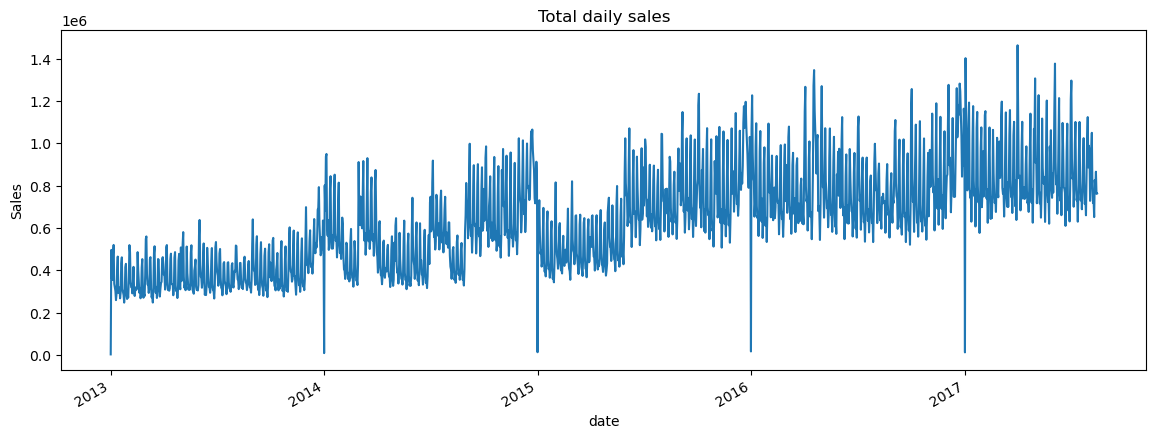

In [ ]:
# df_main['date'] = pd.to_datetime(df_main['date'])
daily = df_main.groupby('date')['sales'].sum()

daily.plot(figsize=(14, 5))
plt.title('Total daily sales')
plt.ylabel('Sales')
plt.show()

<Axes: xlabel='date'>

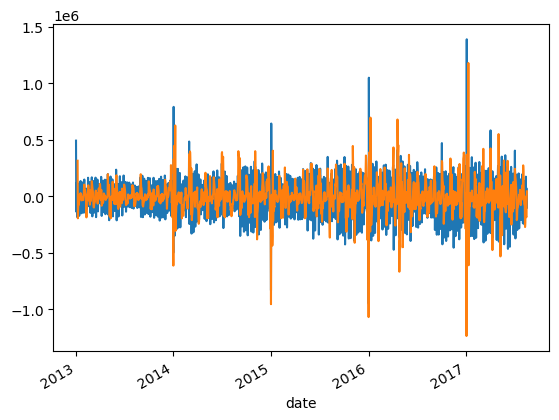

In [ ]:
daily.diff().plot()        # removes the trend
daily.diff(7).plot()       # removes the weekly cycle